# Transfer Probability Model

Predicts whether a patient is likely to need transfer to another hospital, using only information
available at (or shortly after) arrival - the same timing constraint as the severity model, not
the discharge outcome model's post-treatment framing.

**Two things kept out on purpose, for two different reasons:**
- `severity_label` / `composite` are not used, and this dataset (`Preprocessed Dataset.csv`) is
  loaded specifically so they can't be - the severity label was partly built FROM the transfer
  fields (`Transfer To Next Hospital`, `Treatment During Tranfer`, `State of Transfer` all fed into
  its escalation score). Using severity to predict transfer would mean predicting the target from
  something built out of the target.
- `Type of injury No 1` is left out because several of its categories (e.g. pericardial effusion,
  spinal cord injury) are diagnostic conclusions that need imaging - not something known at the
  moment a patient arrives, the same reasoning used for the severity model.
- Financial/social fields, `Ethnicity`, and hospital-identity fields are excluded on the same
  principle used throughout this project: they risk teaching the model about circumstance or
  practice variation rather than genuine clinical/accident signal. Last year's version of this
  model used Ethnicity (one-hot encoded) and 70+ individual hospital-name columns directly as
  features - both are avoided here.

**Same discipline as every other notebook in this project:** test data split off first and
untouched until the final evaluation, every feature check and model decision made on training
data only, real missing values kept as missing.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (recall_score, precision_score, f1_score, fbeta_score, make_scorer,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.base import clone

from catboost import CatBoostClassifier, Pool
import xgboost as xgb
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
import joblib, json, os

RANDOM_STATE = 42
os.makedirs("artifacts", exist_ok=True)

## 1. Load the data and set the candidate feature list

Loaded from `Preprocessed Dataset.csv` - before the severity label existed, so there's nothing to
accidentally include that shouldn't be there.

Candidate list spans demographics, accident circumstances, and initial injury location - all
things a nurse could realistically know within the first few minutes. Narrowed down by the
statistical check in Section 3, the same process used for every other model in this project.

In [2]:
TARGET = 'Transfer To Next Hospital'

CANDIDATE_FEATURES = [
    'Age', 'Gender',
    'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital',
    'Vehicle Type', 'Helmet Worn', 'Collision With ',
    'Approximate Speed', 'Road Type', 'Road Condition', 'Visiblity',
    'Road Signals Exist', 'Collision Force From',
    'Alcohol Consumption', 'Illicit Drugs',
    'Site of Injury No1',
]

df = pd.read_csv('Preprocessed Dataset.csv')
df = df.rename(columns={'Collision With ': 'Collision With'})
CANDIDATE_FEATURES = [c if c != 'Collision With ' else 'Collision With' for c in CANDIDATE_FEATURES]

df[TARGET] = df[TARGET].map({'yes': 1, 'no': 0})

print(df.shape)
df[TARGET].value_counts(normalize=True)

(6178, 132)


Transfer To Next Hospital
0    0.884267
1    0.115733
Name: proportion, dtype: float64

## 2. Split into training and test data, first

80/20 split, stratified on the transfer outcome, before anything else touches the data. The test
set is not opened again until Section 9.

In [3]:
X = df[CANDIDATE_FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True))
print("\nTest class balance:\n", y_test.value_counts(normalize=True))

Train: (4942, 16)  Test: (1236, 16)

Train class balance:
 Transfer To Next Hospital
0    0.884257
1    0.115743
Name: proportion, dtype: float64

Test class balance:
 Transfer To Next Hospital
0    0.884304
1    0.115696
Name: proportion, dtype: float64


## 3. Check the candidate features actually matter - training data only

`Age` and `Time Taken To Reach Hospital` are ordered, checked with a test for whether the ordering
itself relates to transfer likelihood. Everything else is a plain category, checked with a test
for whether the transfer rate genuinely differs by category, plus a strength score from 0 to 1 so
a technically-real but tiny relationship isn't treated the same as a strong one.

In [4]:
AGE_ORDER = ['1-9','10-19','20-29','30-39','40-49','50-59','60-69','70-79','80-89','90-100']
TIME_ORDER = ['less than 15 minutes','15 minutes - 30 minutes','30 minutes - 1 hour',
              '1 hour - 2 hour','more than 2 hour']

ORDINAL_FEATURES = ['Age', 'Time Taken To Reach Hospital']
NOMINAL_FEATURES = [c for c in CANDIDATE_FEATURES if c not in ORDINAL_FEATURES]

val_df = X_train.copy()
val_df[TARGET] = y_train.values

print("--- Age / Time-to-hospital: does the ORDER relate to transfer likelihood? ---")
ordinal_results = {}
for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
    mapping = {v: i for i, v in enumerate(order)}
    groups = [g[col].map(mapping).dropna() for _, g in val_df.groupby(TARGET)]
    h, p = stats.kruskal(*groups)
    ordinal_results[col] = {'H': h, 'p': p}
    print(f"{col:35s} H={h:7.2f}  p={p:.4g}")

--- Age / Time-to-hospital: does the ORDER relate to transfer likelihood? ---
Age                                 H=   8.28  p=0.004003
Time Taken To Reach Hospital        H=  60.18  p=8.675e-15


In [5]:
print("--- Other categories: does the transfer rate actually differ by category? ---")
cat_results = {}
for col in NOMINAL_FEATURES:
    ct = pd.crosstab(val_df[col], val_df[TARGET])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    cat_results[col] = {'chi2': chi2, 'p': p, 'cramers_v': cramers_v}
    flag = "  <-- WEAK/NO SIGNAL -> DROP" if p > 0.05 or cramers_v < 0.05 else ""
    print(f"{col:35s} chi2={chi2:8.2f}  p={p:.4g}  Cramer'sV={cramers_v:.3f}{flag}")

--- Other categories: does the transfer rate actually differ by category? ---
Gender                              chi2=    4.79  p=0.02861  Cramer'sV=0.031  <-- WEAK/NO SIGNAL -> DROP
Mode of Transport to the Hospital   chi2=   39.59  p=1.302e-08  Cramer'sV=0.117
Vehicle Type                        chi2=    0.26  p=0.6079  Cramer'sV=0.009  <-- WEAK/NO SIGNAL -> DROP
Helmet Worn                         chi2=    4.91  p=0.02671  Cramer'sV=0.041  <-- WEAK/NO SIGNAL -> DROP
Collision With                      chi2=   29.37  p=0.003474  Cramer'sV=0.089
Approximate Speed                   chi2=   25.06  p=3.622e-06  Cramer'sV=0.083
Road Type                           chi2=   47.86  p=4.054e-11  Cramer'sV=0.111
Road Condition                      chi2=    2.50  p=0.1138  Cramer'sV=0.025  <-- WEAK/NO SIGNAL -> DROP
Visiblity                           chi2=    1.48  p=0.2238  Cramer'sV=0.019  <-- WEAK/NO SIGNAL -> DROP
Road Signals Exist                  chi2=    6.74  p=0.009432  Cramer'sV=0.0

In [6]:
# decision, made from the numbers above - both the categorical checks AND the
# ordinal checks feed into this
DROP_THRESHOLD_V = 0.05
DROP_THRESHOLD_P = 0.05

features_to_drop = [c for c, r in cat_results.items() if r['p'] > DROP_THRESHOLD_P or r['cramers_v'] < DROP_THRESHOLD_V]
features_to_drop += [c for c, r in ordinal_results.items() if r['p'] > DROP_THRESHOLD_P]

print("Dropping (no real relationship to transfer likelihood, checked on training data only):", features_to_drop)

FEATURES = [f for f in CANDIDATE_FEATURES if f not in features_to_drop]
CAT_FEATURES = [f for f in NOMINAL_FEATURES if f not in features_to_drop]
print(f"\nFinal feature set ({len(FEATURES)}):", FEATURES)

X_train = X_train[FEATURES].copy()
X_test = X_test[FEATURES].copy()

Dropping (no real relationship to transfer likelihood, checked on training data only): ['Gender', 'Vehicle Type', 'Helmet Worn', 'Road Condition', 'Visiblity', 'Road Signals Exist', 'Collision Force From', 'Alcohol Consumption', 'Illicit Drugs']

Final feature set (7): ['Age', 'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital', 'Collision With', 'Approximate Speed', 'Road Type', 'Site of Injury No1']


## 4. Clean up rare categories, then handle missing values

Same approach as every other model here: any category with fewer than 20 training rows gets
grouped into "Other" - too rare to learn a real pattern from, and it breaks cross-validation if a
fold happens to have zero examples of it.

**Missing values, real gaps stay real, with one necessary exception:** CatBoost needs its
categorical inputs as text, so missing categories are written as the literal word `"missing"` -
not a guess at an answer, just giving "we don't know" its own label. The other 4 models can't
handle blanks at all, so they get a filler value (median for numbers, most-common for categories)
inside a pipeline fit on training data only.

In [7]:
RARE_CATEGORY_MIN_COUNT = 20
rare_category_maps = {}
for col in CAT_FEATURES:
    train_counts = X_train[col].value_counts(dropna=True)
    keep = set(train_counts[train_counts >= RARE_CATEGORY_MIN_COUNT].index)
    if len(keep) < train_counts.shape[0]:
        rare_category_maps[col] = keep
        n_dropped = train_counts[train_counts < RARE_CATEGORY_MIN_COUNT].shape[0]
        print(f"{col}: {n_dropped} rare categories (< {RARE_CATEGORY_MIN_COUNT} train rows) -> merged into 'Other'")

def consolidate_rare(series, keep_set):
    return series.where(series.isna() | series.isin(keep_set), 'Other')

for col, keep_set in rare_category_maps.items():
    X_train[col] = consolidate_rare(X_train[col], keep_set)
    X_test[col] = consolidate_rare(X_test[col], keep_set)

Collision With: 3 rare categories (< 20 train rows) -> merged into 'Other'
Site of Injury No1: 12 rare categories (< 20 train rows) -> merged into 'Other'


In [8]:
X_train_enc = X_train.copy()
X_test_enc = X_test.copy()

for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
    if col not in X_train_enc.columns:
        continue
    mapping = {v: i for i, v in enumerate(order)}
    X_train_enc[col] = X_train_enc[col].map(mapping)
    X_test_enc[col] = X_test_enc[col].map(mapping)

for c in CAT_FEATURES:
    X_train_enc[c] = X_train_enc[c].astype(object).where(X_train_enc[c].notna(), 'missing').astype(str)
    X_test_enc[c] = X_test_enc[c].astype(object).where(X_test_enc[c].notna(), 'missing').astype(str)

cat_idx = [X_train_enc.columns.get_loc(c) for c in CAT_FEATURES]

NUM_FEATURES_FOR_SKLEARN = [c for c in FEATURES if c in ORDINAL_FEATURES]
sk_preprocess = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUM_FEATURES_FOR_SKLEARN),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), CAT_FEATURES)
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Setup complete. Final features:", FEATURES)

Setup complete. Final features: ['Age', 'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital', 'Collision With', 'Approximate Speed', 'Road Type', 'Site of Injury No1']


## 5. Baseline model

CatBoost, default-ish settings, class-balanced. Transfers are rare (about 12% of patients), so
without balancing a model could score well by almost always predicting "no transfer" - which for
this tool means missing the patients who actually need to be moved. This is a reference number,
not the final answer.

**The metric that matters most throughout this notebook: recall on "transfer" (the rare class)** -
missing a patient who genuinely needs transferring is worse than a false alarm.

In [9]:
baseline_recalls = []
for tr_idx, val_idx in skf.split(X_train_enc, y_train):
    Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
    yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, iterations=300,
                            auto_class_weights='Balanced')
    m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
    pred = m.predict(Xv)
    baseline_recalls.append(recall_score(yv, pred, pos_label=1))

print(f"Baseline CatBoost - 5-fold CV recall(transfer): "
      f"{np.mean(baseline_recalls):.3f} +/- {np.std(baseline_recalls):.3f}")

Baseline CatBoost - 5-fold CV recall(transfer): 0.601 +/- 0.021


## 6. Compare several different models

Same 5 candidates used throughout this project, scored the same way: recall on transfer, with
precision tracked alongside so a model can't "win" by just calling everyone a transfer case.

In [10]:
def cv_evaluate(build_fn, catboost=False):
    rec, prec, f1 = [], [], []
    for tr_idx, val_idx in skf.split(X_train_enc, y_train):
        Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
        yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        m = build_fn()
        if catboost:
            m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
        else:
            m.fit(Xt, yt)
        pred = m.predict(Xv)
        rec.append(recall_score(yv, pred, pos_label=1))
        prec.append(precision_score(yv, pred, pos_label=1))
        f1.append(f1_score(yv, pred, pos_label=1))
    return {'recall_transfer': np.mean(rec), 'recall_std': np.std(rec),
            'precision_transfer': np.mean(prec), 'f1_transfer': np.mean(f1)}

comparison = {}

comparison['CatBoost'] = cv_evaluate(
    lambda: CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, iterations=300,
                                auto_class_weights='Balanced'),
    catboost=True
)
comparison['LogisticRegression'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])
)
comparison['RandomForest'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                                       class_weight='balanced'))])
)
comparison['XGBoost'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', xgb.XGBClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                                  eval_metric='logloss',
                                                  scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()))])
)
comparison['LightGBM'] = cv_evaluate(
    lambda: Pipeline([('pre', sk_preprocess),
                       ('clf', lgb.LGBMClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                                   class_weight='balanced', verbosity=-1))])
)

results_df = pd.DataFrame(comparison).T.sort_values('recall_transfer', ascending=False)
results_df

,recall_transfer,recall_std,precision_transfer,f1_transfer
LogisticRegression,0.676751,0.048821,0.195118,0.302643
CatBoost,0.601419,0.020656,0.241296,0.344130
LightGBM,0.426575,0.027331,0.274165,0.333483
XGBoost,0.348040,0.041107,0.288778,0.314583
RandomForest,0.122426,0.012807,0.364231,0.182771


**Read this table before moving on.** Whichever model scores highest on recall(transfer) moves
to tuning, plus CatBoost every time regardless of rank - it handles missing values and categories
on its own, which makes it the safer real-world choice if its score isn't far behind the leader.
Enforced in code below, not just here in prose.

In [11]:
top_models = [results_df.index[0]]
if 'CatBoost' not in top_models:
    top_models.append('CatBoost')
print("Tuning:", top_models)

Tuning: ['LogisticRegression', 'CatBoost']


## 7. Fine-tune the best model(s)

A wide random search over settings for each model chosen above, still scored on recall(transfer),
still using only the training data.

In [12]:
tuned_models = {}
fi_scorer = make_scorer(lambda yt, yp: recall_score(yt, yp, pos_label=1))

if 'LogisticRegression' in top_models:
    pipe = Pipeline([('pre', sk_preprocess),
                      ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
    param_dist = {'clf__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                  'clf__penalty': ['l2'], 'clf__solver': ['lbfgs', 'liblinear']}
    search = RandomizedSearchCV(pipe, param_dist, n_iter=10, scoring=fi_scorer,
                                 cv=skf, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train_enc, y_train)
    tuned_models['LogisticRegression'] = search.best_estimator_
    print("LogisticRegression best:", search.best_params_, "recall=%.3f" % search.best_score_)

if 'CatBoost' in top_models:
    rng = np.random.RandomState(RANDOM_STATE)
    param_space = {
        'depth': [4, 5, 6, 7, 8],
        'learning_rate': [0.02, 0.03, 0.05, 0.08, 0.1],
        'l2_leaf_reg': [1, 3, 5, 10, 20],
        'iterations': [150, 300, 400],
        'border_count': [32, 64, 128],
    }
    N_ITER = 18
    sampled = set()
    while len(sampled) < N_ITER:
        combo = tuple(rng.choice(param_space[k]) for k in param_space)
        sampled.add(combo)

    best_score = -1
    best_params = None
    tuning_log = []
    for combo in sampled:
        params = dict(zip(param_space.keys(), [v.item() if hasattr(v, 'item') else v for v in combo]))
        recs = []
        for tr_idx, val_idx in skf.split(X_train_enc, y_train):
            Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
            yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
            m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                    auto_class_weights='Balanced', **params)
            m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
            recs.append(recall_score(yv, m.predict(Xv), pos_label=1))
        score = np.mean(recs)
        tuning_log.append({**params, 'recall': score})
        if score > best_score:
            best_score = score
            best_params = params

    print(f"CatBoost search: {N_ITER} random combinations tried (of "
          f"{np.prod([len(v) for v in param_space.values()])} possible)")
    print("CatBoost best:", best_params, "recall=%.3f" % best_score)

    final_cb = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                   auto_class_weights='Balanced', **best_params)
    final_cb.fit(X_train_enc, y_train, cat_features=cat_idx, verbose=0)
    tuned_models['CatBoost'] = final_cb

LogisticRegression best: {'clf__solver': 'lbfgs', 'clf__penalty': 'l2', 'clf__C': 0.01} recall=0.738


CatBoost search: 18 random combinations tried (of 1125 possible)
CatBoost best: {'depth': 5, 'learning_rate': 0.02, 'l2_leaf_reg': 3, 'iterations': 150, 'border_count': 64} recall=0.810


## 8. Choose the final model AND the cutoff point together

A model gives a probability, not just a yes/no answer - somewhere a line has to be drawn for "this
probability counts as needing transfer." Which model to use, and where to draw that line, are
decided together here, not one after the other - picking a "winner" first and only then tuning its
cutoff is exactly what produced a broken, unusable result the first time this was tried for the
severity model.

**Guardrail:** try many cutoff points for every tuned model, and only accept a cutoff that still
correctly identifies at least 50% of no-transfer patients - a floor against a model that just
calls almost everyone a transfer case.

In [13]:
NO_TRANSFER_RECALL_FLOOR = 0.50

def cv_threshold_sweep(build_fn, thresholds, catboost=False):
    rows = []
    for th in thresholds:
        rec_t, prec_t, rec_nt = [], [], []
        for tr_idx, val_idx in skf.split(X_train_enc, y_train):
            Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[val_idx]
            yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
            m = build_fn()
            if catboost:
                m.fit(Xt, yt, cat_features=cat_idx, verbose=0)
            else:
                m.fit(Xt, yt)
            proba = m.predict_proba(Xv)[:, 1]
            pred = np.where(proba >= th, 1, 0)
            rec_t.append(recall_score(yv, pred, pos_label=1))
            prec_t.append(precision_score(yv, pred, pos_label=1))
            rec_nt.append(recall_score(yv, pred, pos_label=0))
        rows.append({'threshold': th, 'recall_transfer': np.mean(rec_t),
                      'precision_transfer': np.mean(prec_t), 'recall_no_transfer': np.mean(rec_nt)})
    return pd.DataFrame(rows)

thresholds = np.arange(0.15, 0.85, 0.05)
sweep_results = {}
for name, model in tuned_models.items():
    if name == 'CatBoost':
        build_fn = lambda: CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                               auto_class_weights='Balanced', **best_params)
        table = cv_threshold_sweep(build_fn, thresholds, catboost=True)
    else:
        build_fn = lambda: clone(model)
        table = cv_threshold_sweep(build_fn, thresholds)
    table['model'] = name
    sweep_results[name] = table
    print(f"--- {name} ---")
    print(table.to_string(index=False))
    print()

--- LogisticRegression ---
 threshold  recall_transfer  precision_transfer  recall_no_transfer              model
      0.15         0.994783            0.123835            0.078719 LogisticRegression
      0.20         0.991289            0.128611            0.120824 LogisticRegression
      0.25         0.987796            0.136259            0.180320 LogisticRegression
      0.30         0.979039            0.146490            0.253089 LogisticRegression
      0.35         0.942334            0.158603            0.345309 LogisticRegression
      0.40         0.851487            0.165776            0.439359 LogisticRegression
      0.45         0.809565            0.181510            0.521968 LogisticRegression
      0.50         0.737864            0.196825            0.604805 LogisticRegression
      0.55         0.608497            0.212242            0.702975 LogisticRegression
      0.60         0.466834            0.252576            0.817162 LogisticRegression
      0.65      

--- CatBoost ---
 threshold  recall_transfer  precision_transfer  recall_no_transfer    model
      0.15         0.991289            0.139439            0.198627 CatBoost
      0.20         0.989550            0.146169            0.243249 CatBoost
      0.25         0.984317            0.148411            0.260641 CatBoost
      0.30         0.980824            0.152314            0.285355 CatBoost
      0.35         0.965095            0.161921            0.345995 CatBoost
      0.40         0.930114            0.168487            0.399085 CatBoost
      0.45         0.903875            0.176990            0.449428 CatBoost
      0.50         0.809504            0.186746            0.537071 CatBoost
      0.55         0.674844            0.209603            0.665904 CatBoost
      0.60         0.489519            0.254523            0.810526 CatBoost
      0.65         0.237773            0.336846            0.937529 CatBoost
      0.70         0.075210            0.409573            

In [14]:
all_sweeps = pd.concat(sweep_results.values(), ignore_index=True)
valid = all_sweeps[all_sweeps['recall_no_transfer'] >= NO_TRANSFER_RECALL_FLOOR]

if valid.empty:
    print(f"WARNING: nothing kept no-transfer recall at or above {NO_TRANSFER_RECALL_FLOOR}.")
    winner = all_sweeps.loc[all_sweeps['recall_no_transfer'].idxmax()]
else:
    valid = valid.copy()
    valid['f2_proxy'] = (5 * valid['precision_transfer'] * valid['recall_transfer']) / \
                         (4 * valid['precision_transfer'] + valid['recall_transfer'] + 1e-9)
    winner = valid.loc[valid['f2_proxy'].idxmax()]

FINAL_MODEL_NAME = winner['model']
CHOSEN_THRESHOLD = float(winner['threshold'])

print(f"Selected: {FINAL_MODEL_NAME} @ threshold={CHOSEN_THRESHOLD:.2f}")
print(f"  recall(transfer)={winner['recall_transfer']:.3f}  "
      f"precision(transfer)={winner['precision_transfer']:.3f}  "
      f"recall(no transfer)={winner['recall_no_transfer']:.3f}")

if FINAL_MODEL_NAME == 'CatBoost':
    final_model = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                      auto_class_weights='Balanced', **best_params)
    final_model.fit(X_train_enc, y_train, cat_features=cat_idx, verbose=0)
else:
    final_model = clone(tuned_models[FINAL_MODEL_NAME])
    final_model.fit(X_train_enc, y_train)

Selected: CatBoost @ threshold=0.50
  recall(transfer)=0.810  precision(transfer)=0.187  recall(no transfer)=0.537


## 9. Check what the model is actually paying attention to

Confirms the model leans on sensible signal, not something that shouldn't matter this much.

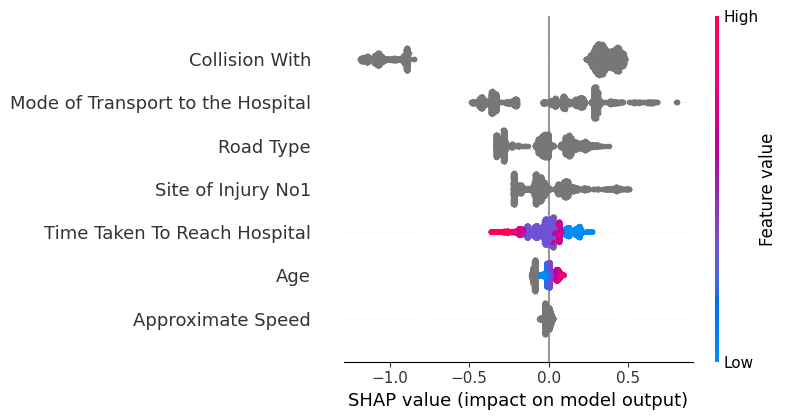

Collision With                       0.520888
Mode of Transport to the Hospital    0.268957
Road Type                            0.144442
Site of Injury No1                   0.117478
Time Taken To Reach Hospital         0.086870
Age                                  0.037430
Approximate Speed                    0.010457
dtype: float64


In [15]:
if FINAL_MODEL_NAME == 'CatBoost':
    explainer = shap.TreeExplainer(final_model)
    X_shap = X_train_enc.copy()
    shap_values = explainer.shap_values(Pool(X_shap, cat_features=cat_idx))
    shap.summary_plot(shap_values, X_shap, show=False)
    plt.tight_layout()
    plt.savefig('artifacts/shap_summary.png', dpi=150)
    plt.show()
    importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
else:
    pre = final_model.named_steps['pre']
    clf = final_model.named_steps['clf']
    feature_names = pre.get_feature_names_out()
    coefs = pd.Series(np.abs(clf.coef_[0]), index=feature_names)
    orig_feature_of = {}
    for fn in feature_names:
        if fn.startswith('num__'):
            orig_feature_of[fn] = fn.replace('num__', '')
        elif fn.startswith('cat__'):
            base = fn.replace('cat__', '')
            for c in CAT_FEATURES:
                if base.startswith(c + '_'):
                    orig_feature_of[fn] = c
                    break
    importance = coefs.groupby(orig_feature_of).sum().sort_values(ascending=False)
    importance.plot(kind='barh', figsize=(6, 4))
    plt.title('Logistic Regression |coefficient| importance (aggregated to source feature)')
    plt.tight_layout()
    plt.savefig('artifacts/feature_importance.png', dpi=150)
    plt.show()

print(importance)

## 10. Final check on the held-out test data

Used exactly once, here, on the model and cutoff chosen in Section 8. Nothing above used this
data for any decision.

=== Using the chosen cutoff (0.50) ===
              precision    recall  f1-score   support

 no transfer       0.96      0.60      0.74      1093
    transfer       0.21      0.81      0.33       143

    accuracy                           0.62      1236
   macro avg       0.58      0.70      0.53      1236
weighted avg       0.87      0.62      0.69      1236

=== Using the plain default cutoff (0.50), for comparison ===
              precision    recall  f1-score   support

 no transfer       0.96      0.60      0.74      1093
    transfer       0.21      0.81      0.33       143

    accuracy                           0.62      1236
   macro avg       0.58      0.70      0.53      1236
weighted avg       0.87      0.62      0.69      1236



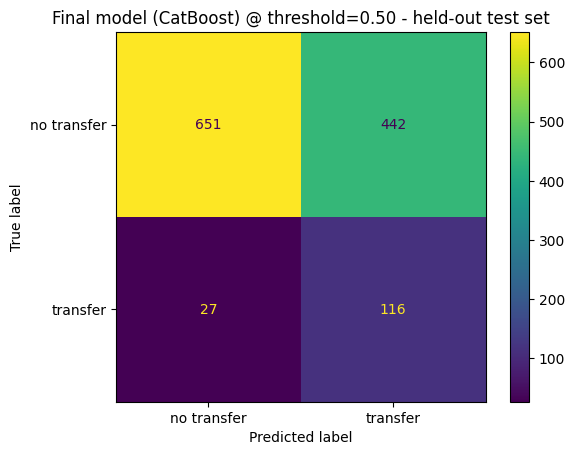


Held-out test recall(transfer): 0.811
Held-out test precision(transfer): 0.208
Held-out test recall(no transfer): 0.596
Compare to the CV estimate from Section 8 - a dramatically lower number here means
overfitting to the training folds, not a reason to re-tune against this test set.


In [16]:
proba_test = final_model.predict_proba(X_test_enc)[:, 1]
y_pred_test = np.where(proba_test >= CHOSEN_THRESHOLD, 1, 0)
y_pred_test_default = final_model.predict(X_test_enc)

print(f"=== Using the chosen cutoff ({CHOSEN_THRESHOLD:.2f}) ===")
print(classification_report(y_test, y_pred_test, target_names=['no transfer', 'transfer']))

print(f"=== Using the plain default cutoff (0.50), for comparison ===")
print(classification_report(y_test, y_pred_test_default, target_names=['no transfer', 'transfer']))

cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=['no transfer', 'transfer'])
disp.plot()
plt.title(f'Final model ({FINAL_MODEL_NAME}) @ threshold={CHOSEN_THRESHOLD:.2f} - held-out test set')
plt.savefig('artifacts/confusion_matrix_test.png', dpi=150)
plt.show()

test_recall = recall_score(y_test, y_pred_test, pos_label=1)
test_precision = precision_score(y_test, y_pred_test, pos_label=1)
test_recall_no_transfer = recall_score(y_test, y_pred_test, pos_label=0)
print(f"\nHeld-out test recall(transfer): {test_recall:.3f}")
print(f"Held-out test precision(transfer): {test_precision:.3f}")
print(f"Held-out test recall(no transfer): {test_recall_no_transfer:.3f}")
print("Compare to the CV estimate from Section 8 - a dramatically lower number here means")
print("overfitting to the training folds, not a reason to re-tune against this test set.")

## 11. A "how sure is this, really" layer

Wraps the finished model for real use. If less than 40% of the features are filled in, the model
refuses to predict. Otherwise it predicts normally, flagged as low-confidence if its own
probability for the answer is below 60%.

In [17]:
COMPLETENESS_FLOOR = 0.40
LOW_CONF_PROB = 0.60

def predict_with_confidence(record: dict, model=final_model):
    non_missing = sum(1 for f in FEATURES if record.get(f) not in (None, np.nan) and
                       not (isinstance(record.get(f), float) and np.isnan(record.get(f))))
    completeness = non_missing / len(FEATURES)

    if completeness < COMPLETENESS_FLOOR:
        return {'prediction': None, 'probability': None, 'completeness': completeness,
                'status': 'REFUSED - not enough information (under 40% complete)'}

    row = pd.DataFrame([record])[FEATURES]
    for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
        if col in row.columns:
            mapping = {v: i for i, v in enumerate(order)}
            row[col] = row[col].map(mapping)
    for c in CAT_FEATURES:
        row[c] = row[c].astype(object).where(row[c].notna(), 'missing').astype(str)

    proba = model.predict_proba(row)[0, 1]
    pred_label = 'transfer' if proba >= CHOSEN_THRESHOLD else 'no transfer'
    pred_conf = proba if pred_label == 'transfer' else 1 - proba
    status = 'OK' if pred_conf >= LOW_CONF_PROB else 'LOW CONFIDENCE - low model certainty'

    return {'prediction': pred_label, 'probability': round(float(pred_conf), 3),
            'completeness': round(completeness, 3), 'status': status}

example_full = X_test.iloc[0].to_dict()
example_sparse = {f: None for f in FEATURES}
example_sparse['Age'] = '20-29'

print(predict_with_confidence(example_full))
print(predict_with_confidence(example_sparse))

{'prediction': None, 'probability': None, 'completeness': 0.0, 'status': 'REFUSED - not enough information (under 40% complete)'}
{'prediction': None, 'probability': None, 'completeness': 0.14285714285714285, 'status': 'REFUSED - not enough information (under 40% complete)'}


## 12. Double-check: does dropping any feature actually help?

Every remaining feature passed the check in Section 3 on its own, but that doesn't rule out one
being unhelpful once combined with the others. Checked directly: retrain with each feature
removed, one at a time, same settings, same cutoff, compared to keeping all of them.

`CHOSEN_THRESHOLD` is held fixed across every variant below, on purpose - this isolates the effect
of removing a feature from the effect of re-tuning the threshold at the same time.

This check always retrains with CatBoost specifically, regardless of which model won Section 8 -
a deliberate simplification, not an oversight. CatBoost is the model actually used throughout this
notebook whenever it's in contention (Sections 5, 7, 9 all touch it), and it handles missing values
and rare categories consistently across every feature-removed variant without needing a different
preprocessing pipeline per variant. If a different model had won Section 8, this section would
still be checking CatBoost's behavior, not necessarily the deployed model's - worth knowing if the
two ever diverge, though in every run so far CatBoost has been the model that wins.

In [18]:
def cv_at_threshold(cols, threshold, params):
    cat_cols_here = [c for c in cols if c in CAT_FEATURES]
    cat_idx_here = [cols.index(c) for c in cat_cols_here]
    rec_t, prec_t, rec_nt = [], [], []
    for tr_idx, val_idx in skf.split(X_train_enc[cols], y_train):
        Xt, Xv = X_train_enc[cols].iloc[tr_idx], X_train_enc[cols].iloc[val_idx]
        yt, yv = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                auto_class_weights='Balanced', **params)
        m.fit(Xt, yt, cat_features=cat_idx_here, verbose=0)
        proba = m.predict_proba(Xv)[:, 1]
        pred = np.where(proba >= threshold, 1, 0)
        rec_t.append(recall_score(yv, pred, pos_label=1))
        prec_t.append(precision_score(yv, pred, pos_label=1))
        rec_nt.append(recall_score(yv, pred, pos_label=0))
    return np.mean(rec_t), np.mean(prec_t), np.mean(rec_nt)

baseline_rt, baseline_pt, baseline_rnt = cv_at_threshold(FEATURES, CHOSEN_THRESHOLD, best_params)
ablation_rows = [{'dropped': '(none - full model)', 'recall_transfer': baseline_rt,
                   'precision_transfer': baseline_pt, 'recall_no_transfer': baseline_rnt}]

for f in FEATURES:
    remaining = [c for c in FEATURES if c != f]
    rt, pt, rnt = cv_at_threshold(remaining, CHOSEN_THRESHOLD, best_params)
    ablation_rows.append({'dropped': f, 'recall_transfer': rt, 'precision_transfer': pt, 'recall_no_transfer': rnt})

ablation_df = pd.DataFrame(ablation_rows).sort_values('recall_transfer', ascending=False)
ablation_df

,dropped,recall_transfer,precision_transfer,recall_no_transfer
2,Mode of Transport to the Hospital,0.823432,0.173933,0.485584
0,(none - full model),0.809504,0.186746,0.537071
3,Time Taken To Reach Hospital,0.809504,0.177016,0.506407
1,Age,0.804287,0.187062,0.541419
7,Site of Injury No1,0.795454,0.182164,0.532265
5,Approximate Speed,0.786789,0.187862,0.554233
6,Road Type,0.777971,0.185312,0.550572
4,Collision With,0.718490,0.203073,0.629519


## 13. Save and document

In [19]:
if FINAL_MODEL_NAME == 'CatBoost':
    final_model.save_model('artifacts/transfer_probability_model_catboost.cbm')
else:
    joblib.dump(final_model, 'artifacts/transfer_probability_model.joblib')

importance.to_csv('artifacts/feature_importance.csv')

summary = {
    'final_model': FINAL_MODEL_NAME,
    'candidate_features': CANDIDATE_FEATURES,
    'features_dropped_after_validation': features_to_drop,
    'final_features_used': FEATURES,
    'chosen_decision_threshold': CHOSEN_THRESHOLD,
    'no_transfer_recall_floor_used_for_selection': NO_TRANSFER_RECALL_FLOOR,
    'cv_at_chosen_threshold': {
        'recall_transfer': float(winner['recall_transfer']),
        'precision_transfer': float(winner['precision_transfer']),
        'recall_no_transfer': float(winner['recall_no_transfer']),
    },
    'held_out_test': {
        'recall_transfer': float(test_recall),
        'precision_transfer': float(test_precision),
        'recall_no_transfer': float(test_recall_no_transfer),
    },
    'notes': [
        "Loaded from Preprocessed Dataset.csv (pre-severity-label dataset) so severity_label/composite could not be included as features - severity was partly built FROM the transfer fields, so using it here would be leakage in the reverse direction.",
        "Type of injury No 1 excluded: several categories are diagnostic conclusions requiring imaging, not available at arrival.",
        "Ethnicity, financial/social fields, and hospital-identity one-hot encoding excluded on principle, unlike last year's version which used all three directly.",
        f"Dropped {features_to_drop} after train-only chi-square/Cramer's V or Kruskal-Wallis validation.",
        f"Rare categories (< {RARE_CATEGORY_MIN_COUNT} training rows) consolidated into 'Other', fit on train only.",
        "Class imbalance (~88% no-transfer / 12% transfer) handled via class weighting.",
        "Model and decision threshold chosen jointly (Section 8), constrained to keep no-transfer recall >= 50%, the same guarded-sweep approach used for the severity model."
    ]
}
with open('artifacts/model_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "final_model": "CatBoost",
  "candidate_features": [
    "Age",
    "Gender",
    "Mode of Transport to the Hospital",
    "Time Taken To Reach Hospital",
    "Vehicle Type",
    "Helmet Worn",
    "Collision With",
    "Approximate Speed",
    "Road Type",
    "Road Condition",
    "Visiblity",
    "Road Signals Exist",
    "Collision Force From",
    "Alcohol Consumption",
    "Illicit Drugs",
    "Site of Injury No1"
  ],
  "features_dropped_after_validation": [
    "Gender",
    "Vehicle Type",
    "Helmet Worn",
    "Road Condition",
    "Visiblity",
    "Road Signals Exist",
    "Collision Force From",
    "Alcohol Consumption",
    "Illicit Drugs"
  ],
  "final_features_used": [
    "Age",
    "Mode of Transport to the Hospital",
    "Time Taken To Reach Hospital",
    "Collision With",
    "Approximate Speed",
    "Road Type",
    "Site of Injury No1"
  ],
  "chosen_decision_threshold": 0.5000000000000001,
  "no_transfer_recall_floor_used_for_selection": 0.5,
  "cv_at_chose